In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Make src/ available for importing project modules
sys.path.insert(0, str(Path("../src").resolve()))

from strategies.ev_strategy import apply_ev_strategy

df = pd.read_csv("../data/processed/zbw_features.csv")

results = apply_ev_strategy(df)

results["matches_strategy"] = (
    results["decision"] == results["ev_strategy"]
)

print(f"Total decisions: {len(results)}")
print(f"Agreement rate: {results['matches_strategy'].mean():.2%}")

Total decisions: 2136
Agreement rate: 86.70%


## Comparing the EV Strategy with Actual Decisions

We compare the simple EV strategy's recommendations with contestants' actual decisions using a confusion matrix.

This helps identify when contestants accepted or rejected offers differently from our EV benchmark.

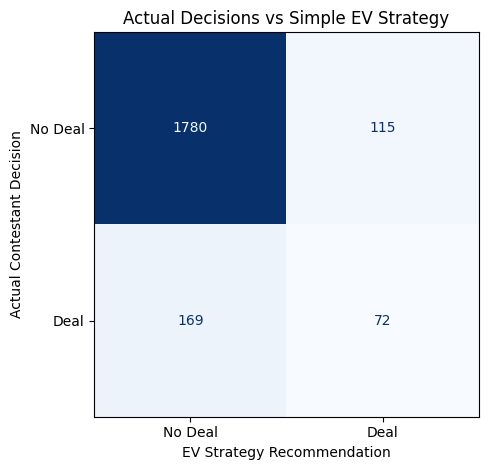

No Deal when EV strategy recommends Deal: 115
Deal when EV strategy recommends No Deal: 169


In [2]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Rows = actual decisions, columns = EV strategy recommendations
cm = confusion_matrix(
    results["decision"],
    results["ev_strategy"],
    labels=[0, 1]
)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Deal", "Deal"]
)

disp.plot(cmap="Blues", values_format="d", colorbar=False)

plt.title("Actual Decisions vs Simple EV Strategy")
plt.xlabel("EV Strategy Recommendation")
plt.ylabel("Actual Contestant Decision")
plt.tight_layout()
plt.show()

# Print the disagreement counts
print("No Deal when EV strategy recommends Deal:", cm[0, 1])
print("Deal when EV strategy recommends No Deal:", cm[1, 0])

   round  total_decisions  disagreements  disagreement_rate
0      1              291              0               0.00
1      2              291              0               0.00
2      3              291              4               1.37
3      4              288             17               5.90
4      5              274             29              10.58
5      6              250             51              20.40
6      7              210             74              35.24
7      8              150             69              46.00
8      9               91             40              43.96


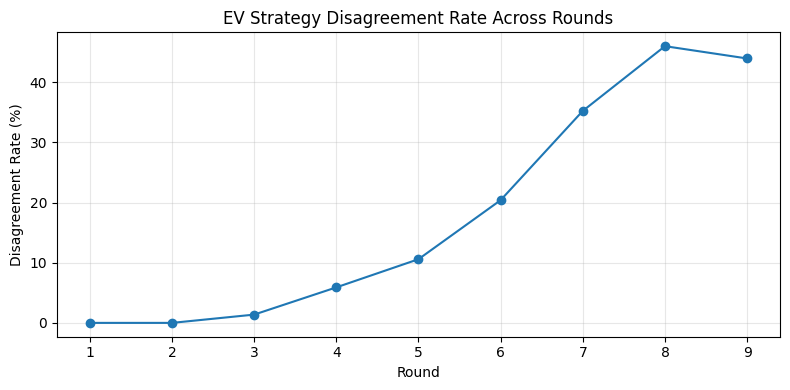

In [3]:
round_comparison = (
    results.groupby("round")
    .agg(
        total_decisions=("decision", "size"),
        disagreements=("matches_strategy", lambda x: (~x).sum())
    )
    .reset_index()
)

round_comparison["disagreement_rate"] = (
    round_comparison["disagreements"]
    / round_comparison["total_decisions"] * 100
)

print(round_comparison.round(2))

plt.figure(figsize=(8, 4))
plt.plot(
    round_comparison["round"],
    round_comparison["disagreement_rate"],
    marker="o"
)

plt.xlabel("Round")
plt.ylabel("Disagreement Rate (%)")
plt.title("EV Strategy Disagreement Rate Across Rounds")
plt.xticks(round_comparison["round"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Disagreement Rates Across Rounds

Disagreements between actual contestant decisions and the simple EV strategy increase across rounds. Early rounds show almost no disagreement, while rounds 8 and 9 have disagreement rates of approximately 45%.

This may be because banker offers become more competitive relative to board EV in later rounds, making decisions less straightforward.

The results suggest that round number, future offers, and risk preferences may be important when developing a more advanced decision strategy.

In [4]:
results["disagreement_type"] = "Agreement"

results.loc[
    (results["decision"] == 1) &
    (results["ev_strategy"] == 0),
    "disagreement_type"
] = "Accepted below EV"

results.loc[
    (results["decision"] == 0) &
    (results["ev_strategy"] == 1),
    "disagreement_type"
] = "Rejected at/above EV"

disagreement_by_round = pd.crosstab(
    results["round"],
    results["disagreement_type"]
)

print(disagreement_by_round)

disagreement_type  Accepted below EV  Agreement  Rejected at/above EV
round                                                                
1                                  0        291                     0
2                                  0        291                     0
3                                  3        287                     1
4                                 14        271                     3
5                                 23        245                     6
6                                 34        199                    17
7                                 45        136                    29
8                                 36         81                    33
9                                 14         51                    26


### Types of Disagreement Across Rounds

Accepting offers below board EV is the more common disagreement overall (169 decisions), compared with rejecting offers at or above EV (115 decisions).

Both disagreement types become more frequent in later rounds. By round 9, rejecting offers at or above EV is more common than accepting below EV.

These results suggest that a simple comparison between the current offer and board EV does not fully explain contestant decisions, particularly in later rounds. Future banker offers, remaining prize distributions, and risk preferences may help explain these differences.